# Sección 1: Importación de Librerías y Carga de Datos

En esta sección se importan las dependencias del proyecto, se carga el conjunto de datos con codificación `utf-8-sig`, se revisan las dimensiones y primeros registros, y se valida la presencia íntegra de las columnas del diccionario.

In [ ]:
# Importación de librerías principales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import imblearn
from IPython.display import display

# Configuración básica de visualización
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print(f"Pandas versión: {pd.__version__}")

In [ ]:
# Carga del archivo CSV con codificación utf-8-sig
df = pd.read_csv("transacciones_bancarias_fraude.csv", encoding="utf-8-sig")

# Dimensiones del dataset
print(f"Dimensiones (filas, columnas): {df.shape}")

# Primeras 5 filas del dataset
df.head()

In [ ]:
# Información general del DataFrame (tipos de datos y no nulos)
df.info()

In [ ]:
# Verificación de columnas del diccionario de datos
columnas_esperadas = [
    "id_transaccion", "monto", "hora_transaccion", "distancia_ubicacion",
    "frecuencia_transacciones", "monto_promedio_cliente", "dispositivo_nuevo",
    "ubicacion_nueva", "tipo_transaccion", "canal", "metodo_autenticacion",
    "antiguedad_cliente_meses", "fraude"
]

columnas_actuales = df.columns.tolist()
columnas_faltantes = [col for col in columnas_esperadas if col not in columnas_actuales]
columnas_extra = [col for col in columnas_actuales if col not in columnas_esperadas]

print(f"Columnas esperadas: {len(columnas_esperadas)} | Columnas detectadas: {len(columnas_actuales)}")
if not columnas_faltantes and not columnas_extra:
    print("✓ Verificación exitosa: Todas las columnas del diccionario están presentes.")
else:
    if columnas_faltantes:
        print(f"✗ Columnas faltantes: {columnas_faltantes}")
    if columnas_extra:
        print(f"✗ Columnas no esperadas: {columnas_extra}")

# Sección 2: Análisis Exploratorio de Datos (EDA)

Exploración de la calidad de los datos, distribución de variables categóricas y numéricas, balance de la variable objetivo y detección de valores atípicos.

### 2.a Valores faltantes: conteo y porcentaje por columna

In [5]:
# Conteo y porcentaje de valores faltantes por columna
nulos = df.isnull().sum()
pct_nulos = (df.isnull().mean() * 100).round(2)
tabla_nulos = pd.DataFrame({"Faltantes": nulos, "Porcentaje (%)": pct_nulos})
display(tabla_nulos[tabla_nulos["Faltantes"] > 0])

,Faltantes,Porcentaje (%)
distancia_ubicacion,305,1.01
monto_promedio_cliente,486,1.62
metodo_autenticacion,247,0.82


**Interpretación:** Solo 3 variables presentan valores faltantes: `monto_promedio_cliente` (486 registros, 1,62 %), `distancia_ubicacion` (305, 1,01 %) y `metodo_autenticacion` (247, 0,82 %). Todos están por debajo del 2 %, por lo que no conviene eliminar filas: se imputarán (mediana en las numéricas por su asimetría y moda en la categórica). La imputación se ajustará solo con el conjunto de entrenamiento, dentro del pipeline, para evitar fuga de información.

### 2.b Duplicados exactos

In [6]:
# Conteo de registros duplicados exactos
num_duplicados = df.duplicated().sum()
print(f"Total de duplicados exactos: {num_duplicados}")

Total de duplicados exactos: 90


**Interpretación:** Se detectaron 90 registros duplicados exactos (≈0,30 %). Se eliminarán antes de dividir en entrenamiento y prueba; de lo contrario, una misma transacción podría caer en ambos conjuntos y las métricas saldrían infladas (data leakage).

### 2.c Distribución de variables categóricas

,Conteo,Porcentaje (%)
tipo_transaccion,,
Compra,14780,49.12
Pago,7120,23.66
Transferencia,4878,16.21
Retiro,3312,11.01


,Conteo,Porcentaje (%)
canal,,
Aplicación móvil,10433,34.67
POS,10266,34.12
Web,6925,23.01
Cajero,2466,8.20


,Conteo,Porcentaje (%)
metodo_autenticacion,,
Tarjeta,15424,51.26
Clave,5918,19.67
Biometría,5686,18.90
Token,2815,9.36
NaN,247,0.82


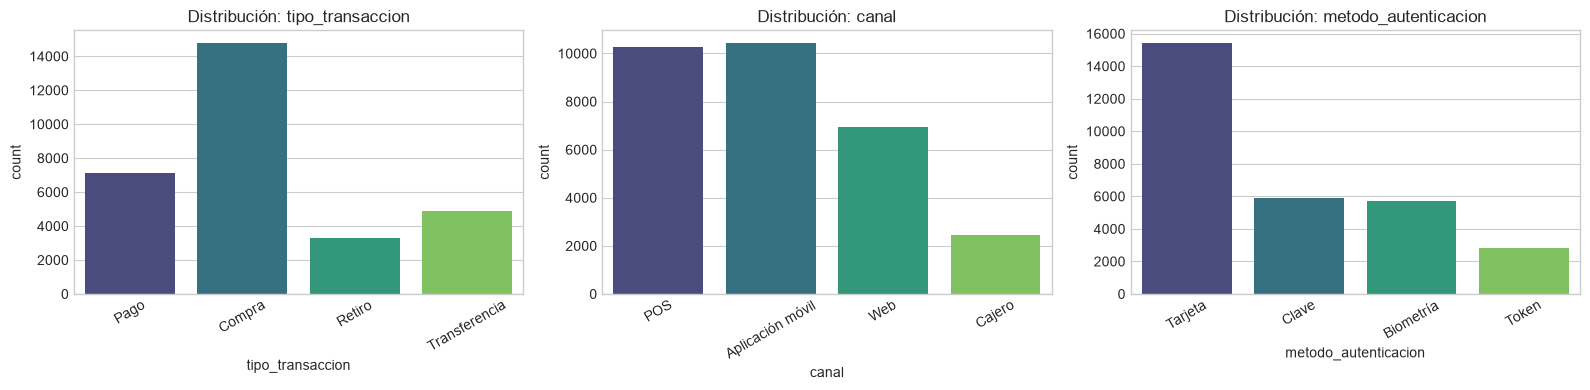

In [7]:
# Distribución de variables categóricas con conteos, porcentajes y countplots
cat_cols = ["tipo_transaccion", "canal", "metodo_autenticacion"]

for col in cat_cols:
    conteo = df[col].value_counts(dropna=False)
    pct = (df[col].value_counts(normalize=True, dropna=False) * 100).round(2)
    display(pd.DataFrame({"Conteo": conteo, "Porcentaje (%)": pct}))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, hue=col, ax=axes[i], palette="viridis", legend=False)
    axes[i].set_title(f"Distribución: {col}")
    axes[i].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Interpretación:** `tipo_transaccion` está dominada por Compra (49,12 %), seguida de Pago (23,66 %), Transferencia (16,21 %) y Retiro (11,01 %). En `canal` predominan Aplicación móvil (34,67 %) y POS (34,12 %), con Web (23,01 %) y Cajero (8,20 %) menos frecuentes. En `metodo_autenticacion` domina Tarjeta (51,26 %); el resto se reparte entre Clave, Biometría y Token (9,36 %), y hay 0,82 % de nulos. Todas tienen pocas categorías y ninguna con frecuencia insignificante, por lo que One-Hot Encoding es adecuado y no genera demasiadas columnas.

### 2.d Variables numéricas: estadísticas descriptivas e histogramas

,monto,hora_transaccion,distancia_ubicacion,frecuencia_transacciones,monto_promedio_cliente,dispositivo_nuevo,ubicacion_nueva,antiguedad_cliente_meses,fraude
count,30090.00,30090.00,29785.00,30090.00,29604.00,30090.00,30090.00,30090.00,30090.00
mean,106.72,13.62,11.79,2.20,80.37,0.09,0.09,53.83,0.03
std,147.87,4.79,21.02,1.71,53.74,0.28,0.28,34.82,0.16
min,2.58,0.00,0.00,0.00,7.03,0.00,0.00,1.00,0.00
25%,39.74,11.00,2.76,1.00,44.87,0.00,0.00,28.00,0.00
50%,69.56,14.00,6.69,2.00,67.07,0.00,0.00,47.00,0.00
75%,123.48,17.00,13.60,3.00,100.59,0.00,0.00,72.00,0.00
max,5000.00,23.00,500.00,15.00,1269.98,1.00,1.00,240.00,1.00


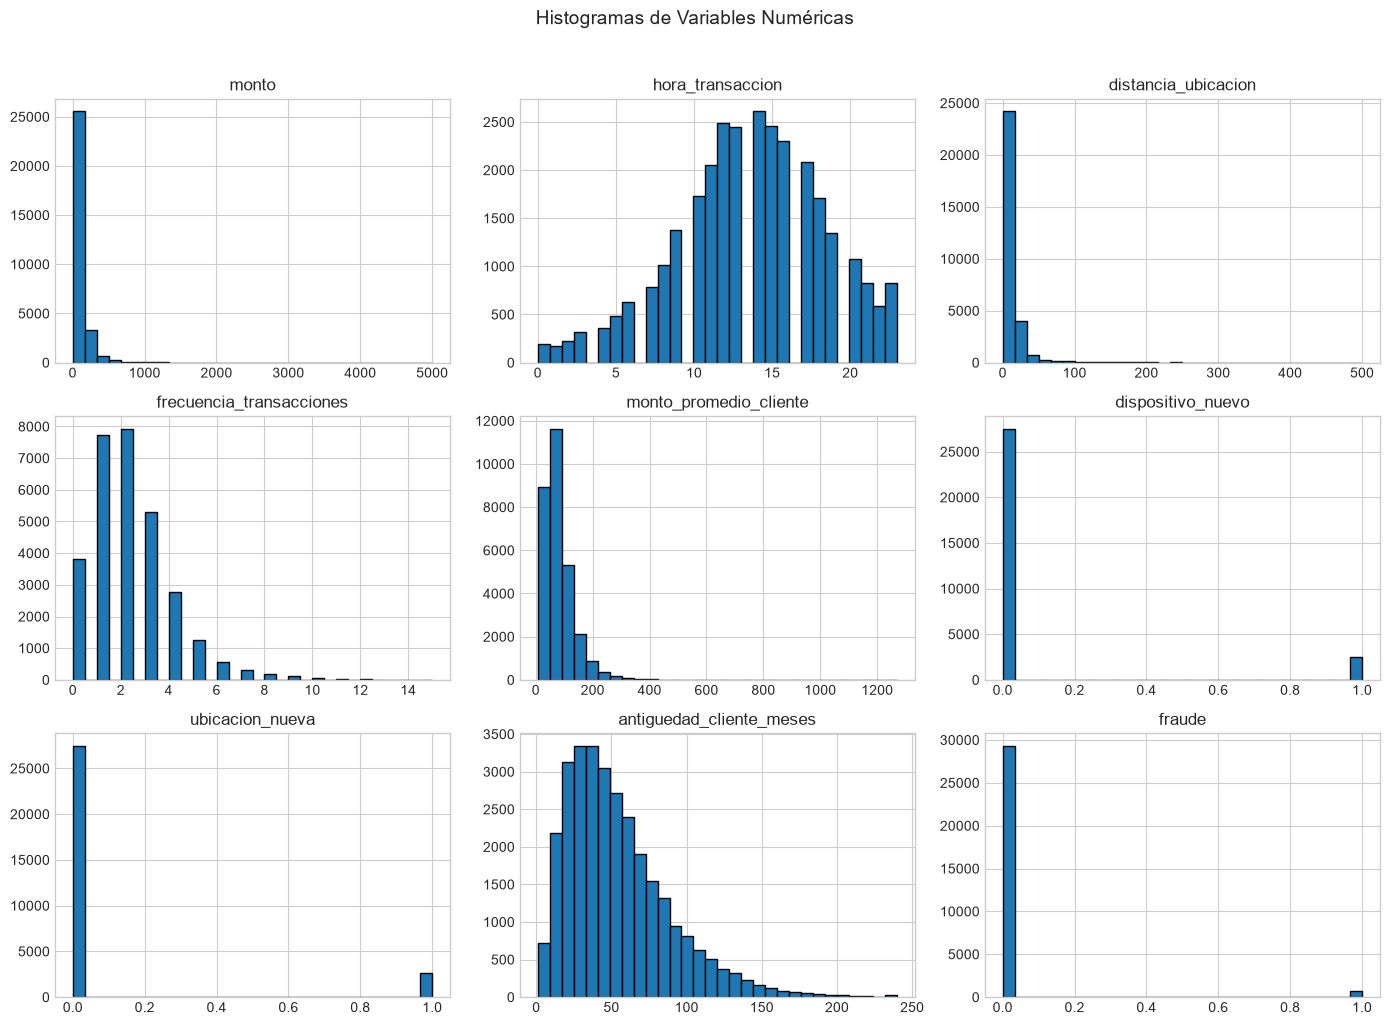

In [8]:
# Estadísticas descriptivas de variables numéricas
display(df.describe().round(2))

# Histogramas de distribución para variables numéricas
num_cols = df.select_dtypes(include=[np.number]).columns
df[num_cols].hist(figsize=(14, 10), bins=30, edgecolor="black", grid=True)
plt.suptitle("Histogramas de Variables Numéricas", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

**Interpretación:** `monto`, `distancia_ubicacion`, `monto_promedio_cliente` y `antiguedad_cliente_meses` presentan asimetría positiva: la media supera a la mediana (por ejemplo, monto 106,72 vs 69,56; distancia 11,79 vs 6,69) y existen valores muy altos (monto máximo 5.000, distancia máxima 500 km). `hora_transaccion` se concentra entre las 11 y las 18 h (mediana 14), con poca actividad en la madrugada. `frecuencia_transacciones` tiene mediana 2 y máximo 15. `dispositivo_nuevo` y `ubicacion_nueva` son binarias y valen 1 en cerca del 9 % de los casos. Como las escalas son muy distintas (monto hasta 5.000 frente a variables 0/1), se aplicará estandarización, necesaria para Regresión Logística, KNN, SVM y MLP.

### 2.e Proporción de fraude vs legítimas

,Conteo,Porcentaje (%)
fraude,,
0,29321,97.44
1,769,2.56


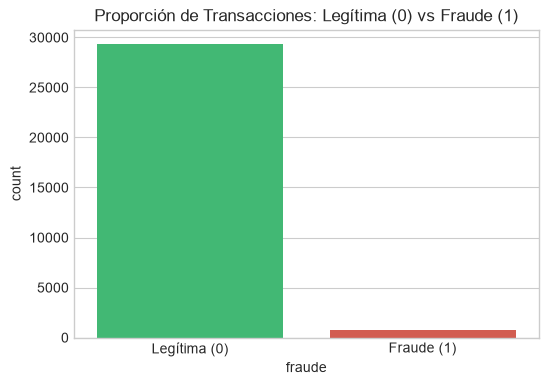

In [9]:
# Conteo y porcentaje de la variable objetivo (fraude)
conteo_fraude = df["fraude"].value_counts()
pct_fraude = (df["fraude"].value_counts(normalize=True) * 100).round(2)
display(pd.DataFrame({"Conteo": conteo_fraude, "Porcentaje (%)": pct_fraude}))

# Gráfico de barras de la variable objetivo
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="fraude", hue="fraude", palette=["#2ecc71", "#e74c3c"], legend=False)
ax.set_title("Proporción de Transacciones: Legítima (0) vs Fraude (1)")
ax.set_xticks([0, 1], labels=["Legítima (0)", "Fraude (1)"])
plt.show()

**Interpretación:** Hay 29.321 transacciones legítimas (97,44 %) y 769 fraudulentas (2,56 %): una relación aproximada de 38 a 1, lo que confirma un problema de clases desbalanceadas. Un modelo que clasificara todo como legítimo tendría un 97,44 % de Accuracy sin detectar ningún fraude (Recall = 0), por eso el análisis se basará en Recall, Precision, F1 y AUC-ROC, usando división y validación cruzada estratificadas y un tratamiento explícito del desbalance.

### 2.f Detección de valores atípicos (regla IQR y boxplots)

,Q1,Q3,IQR,Límite Inf,Límite Sup,Atípicos,Porcentaje (%)
Variable,,,,,,,
monto,39.74,123.48,83.73,-85.86,249.08,2236,7.43
distancia_ubicacion,2.76,13.60,10.84,-13.50,29.86,1907,6.40
frecuencia_transacciones,1.00,3.00,2.00,-2.00,6.00,732,2.43


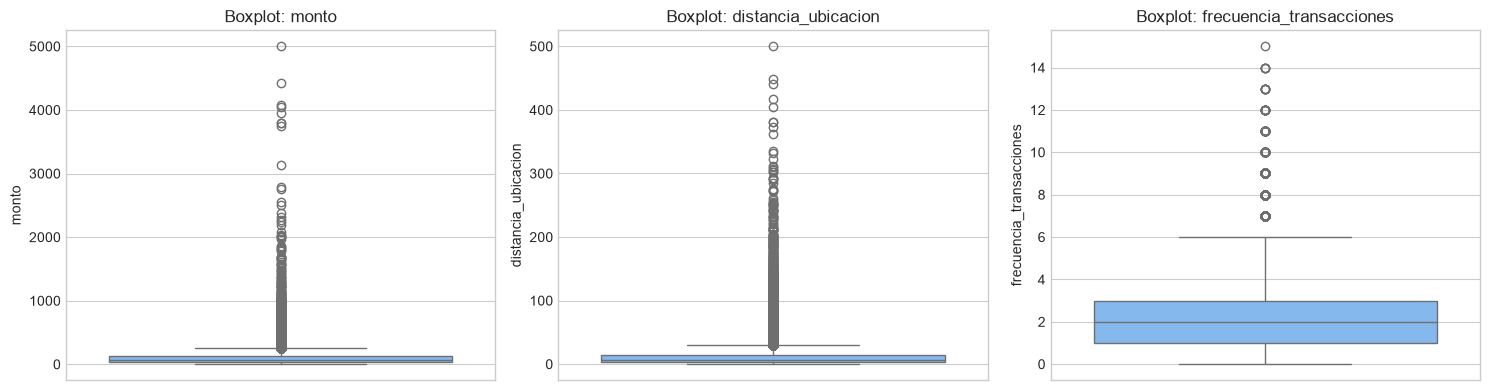

In [10]:
# Detección de valores atípicos por regla IQR
cols_atipicos = ["monto", "distancia_ubicacion", "frecuencia_transacciones"]
iqr_summary = []
for col in cols_atipicos:
    s = df[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    outliers = ((s < lim_inf) | (s > lim_sup)).sum()
    pct = (outliers / len(s)) * 100
    iqr_summary.append({
        "Variable": col, "Q1": round(q1, 2), "Q3": round(q3, 2), "IQR": round(iqr, 2),
        "Límite Inf": round(lim_inf, 2), "Límite Sup": round(lim_sup, 2),
        "Atípicos": outliers, "Porcentaje (%)": round(pct, 2)
    })
display(pd.DataFrame(iqr_summary).set_index("Variable"))

# Boxplots para visualización de atípicos
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(cols_atipicos):
    sns.boxplot(y=df[col], ax=axes[i], color="#74b9ff")
    axes[i].set_title(f"Boxplot: {col}")
plt.tight_layout()
plt.show()

**Interpretación:** Por la regla del IQR hay 2.236 atípicos en `monto` (7,43 %, límite superior 249,08), 1.907 en `distancia_ubicacion` (6,40 %, límite 29,86) y 732 en `frecuencia_transacciones` (2,43 %, límite 6). No se eliminarán: montos altos, distancias grandes y ráfagas de transacciones son comportamientos típicos de fraude, así que contienen información que el modelo debe aprender. Como los atípicos (7,43 % en monto) superan la tasa de fraude (2,56 %), no todos son fraudes: también hay clientes legítimos con compras grandes o lejanas.